Isaac Noe

10/18/2026

Code lab 7 — Engine Demo

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import engine_big as engine

Part A — Build the Core Engine (35 points)

In [9]:
# Part 1 - 3
# Implement the four classes
# Add a force accumulator pattern and a data-recording mechanism to the World
Body = engine.Body
Gravity = engine.Gravity
Drag = engine.Drag
Spring = engine.Spring
Newton_Gravity = engine.NewtonGravity
EulerCromer = engine.EulerCromer
Verlet = engine.Verlet
World = engine.World

Part B — Validate Against Your Old Labs (35 points)

Maximum trajectory difference: 0.000e+00 m
Maximum engine/reference energy difference: 1.933e-12 J
Maximum difference from predicted discrete energy: 1.137e-12 J
Total-energy change: -21.653 J


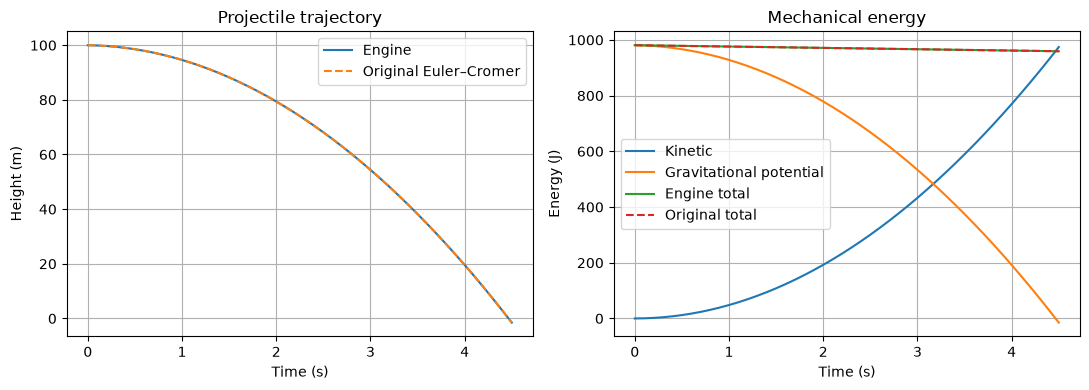

In [ ]:
# Part 1
# Projectile (Labs 1–2)
# Original Process
def simulate_freefall(h, dt, g=9.81, m=1.0):
    y, vy = h, 0.0
    t = 0.0

    t_arr, y_arr, vy_arr = [t], [y], [vy]
    pe_arr = [m * g * y]
    ke_arr = [0.5 * m * vy**2]
    total_energy_arr = [pe_arr[-1] + ke_arr[-1]]

    while y >= 0:
        ay = -g

        # Euler update
        y = y + vy * dt
        vy = vy + ay * dt
        t = t + dt

        t_arr.append(t)
        y_arr.append(y)
        vy_arr.append(vy)

        pe = m * g * y
        ke = 0.5 * m * vy**2
        pe_arr.append(pe)
        ke_arr.append(ke)
        total_energy_arr.append(pe + ke)

    return t_arr, y_arr, vy_arr, pe_arr, ke_arr, total_energy_arr

g = 9.81         # m/s², gravitational acceleration
dt = .1      # time step in seconds
h = 100          # starting height 

t_cal, y_cal, vy_cal, pe_cal, ke_cal, total_energy_cal = simulate_freefall(h, dt)

# Storage lists for plotting
y_ex, t_ex = [h], [0.0]
vy_ex = 0
# Euler integration loop
t = 0.0
while h >= 0.0:
    # Compute acceleration (only gravity here)
    ay = -g

    # Update velocity (Euler)
    vy_ex = vy_ex + ay * dt

    # Update position (Euler)
    h = h + vy_ex * dt

    t += dt
    y_ex.append(h)
    t_ex.append(t)

# Engine Process
proj_mass = 1.0

proj_world = World(EulerCromer())
proj_body = Body(mass=proj_mass, pos=[0.0, y_ex[0]], vel=[0.0, 0.0], radius=0.01)
proj_world.add_body(proj_body)
proj_world.add_force(Gravity(g=g))

list(map(lambda _: proj_world.step(dt), np.arange(len(y_ex) - 1)))

proj_history = proj_world.history
proj_time = np.fromiter((state["time"] for state in proj_history), dtype=float)
proj_y = np.fromiter((state["positions"][0, 1] for state in proj_history), dtype=float)
proj_kinetic = np.fromiter((state["kinetic_energy"] for state in proj_history), dtype=float)
proj_potential = np.fromiter((state["potential_energy"] for state in proj_history), dtype=float)
proj_total = np.fromiter((state["total_energy"] for state in proj_history), dtype=float)

# Reference Euler–Cromer velocity and mechanical energy.
step_number = np.arange(len(y_ex))
original_vy = -g * dt * step_number
original_energy = (0.5 * proj_mass * original_vy**2 + proj_mass * g * np.asarray(y_ex))

expected_energy = original_energy[0] - (0.5 * proj_mass * g**2 * dt**2 * step_number)

print(f"Maximum trajectory difference: "
      f"{np.max(np.abs(proj_y - np.asarray(y_ex))):.3e} m")
print(f"Maximum engine/reference energy difference: "
      f"{np.max(np.abs(proj_total - original_energy)):.3e} J")
print(f"Maximum difference from predicted discrete energy: "
      f"{np.max(np.abs(proj_total - expected_energy)):.3e} J")
print(f"Total-energy change: "
      f"{proj_total[-1] - proj_total[0]:.3f} J")

# Graph
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(proj_time, proj_y, label="Engine")
axes[0].plot(t_ex, y_ex, "--", label="Original Lab")
axes[0].set(xlabel="Time (s)", ylabel="Height (m)", title="Projectile trajectory")
axes[0].legend()
axes[0].grid()

axes[1].plot(proj_time, proj_kinetic, label="Kinetic")
axes[1].plot(proj_time, proj_potential, label="Gravitational potential")
axes[1].plot(proj_time, proj_total, label="Engine total")
axes[1].plot(t_ex, original_energy, "--", label="Original total")
axes[1].set(xlabel="Time (s)", ylabel="Energy (J)", title="Mechanical energy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

These graphs show the original projectile lab's trajectory and total energy as well as the engine's trajectory of the same object and its Kinetic, Potential, and total energy. Showing that the outputs of both processes are the same.

Reference period: 6.283159 s
Engine period:    6.283159 s
Theoretical period: 6.283185 s
Maximum |x_engine - x_reference|: 4.274e-14 m
Maximum |v_engine - v_reference|: 3.797e-14 m/s
Engine total-energy range: 5.000e-03 J
Maximum momentum magnitude: 0.000e+00 kg·m/s


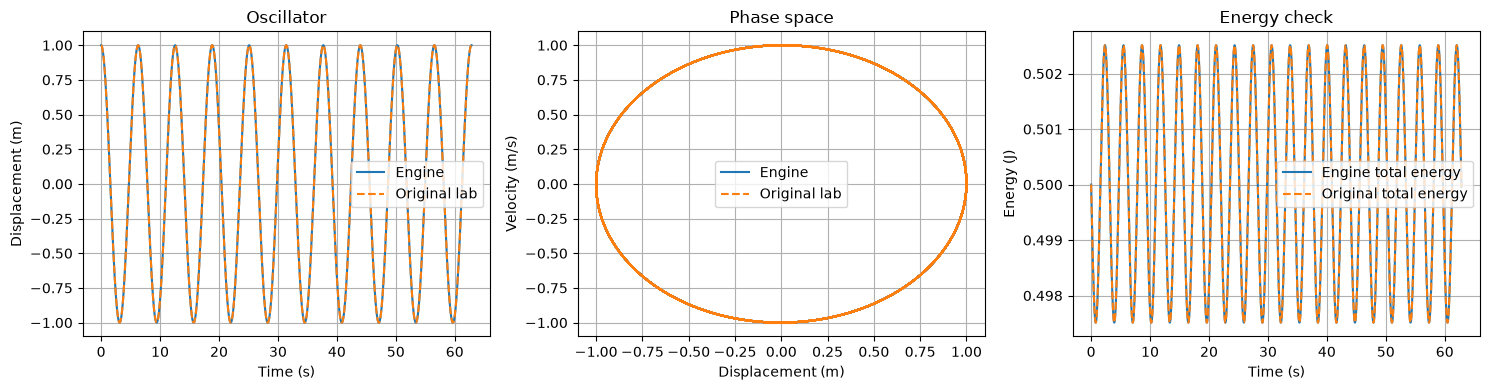

In [11]:
# Part 2
# Oscillator (Labs 3)
# Orignal Process

# Parameters
k = 1.0     # spring constant (N/m)
m = 1.0     # mass (kg)
omega0 = np.sqrt(k / m)   # natural frequency
T = 2 * np.pi / omega0      # period
t_exact = np.linspace(0, 10*T, 2000)
dt = 0.01

# Initial conditions
x0 = 1.0    # initial displacement (m)
v0 = 0.0    # released from rest

def simulate_sho(dt, n_periods=10):
    """Simulate SHO. Returns t, x, v, E arrays."""
    t_max = n_periods * T
    x, v = x0, v0
    ts, xs, vs, Es = [0], [x], [v], [0.5*k*x**2 + 0.5*m*v**2]
    t = 0.0

    while t < t_max:
        a = -(k / m) * x

        # Euler-Cromer update
        v = v + a * dt       # velocity first
        x = x + v * dt       # then position with new v
        E = 0.5 * k * x**2 + 0.5 * m * v**2

        t += dt
        
        ts.append(t); xs.append(x); vs.append(v); Es.append(E)

    return np.array(ts), np.array(xs), np.array(vs), np.array(Es)

# Engine Process
osc_original_t, osc_original_x, osc_original_v, osc_original_E = simulate_sho(dt)

osc_world = World(EulerCromer())
osc_left = Body(mass=2.0, pos=[-5.5, 0.0], vel=[0.0, 0.0], radius=0.01)
osc_right = Body(mass=2.0, pos=[5.5, 0.0], vel=[0.0, 0.0], radius=0.01)
osc_world.add_body(osc_left)
osc_world.add_body(osc_right)
osc_world.add_force(Spring(osc_left, osc_right, stiffness=1.0, rest_length=10.0))

list(map(lambda _: osc_world.step(dt), range(len(osc_original_t) - 1)))

osc_history = osc_world.history
osc_t = np.fromiter((s["time"] for s in osc_history), dtype=float)
osc_x = np.fromiter((s["positions"][0, 0] * -1 + s["positions"][1, 0] - 10.0 for s in osc_history), dtype=float,)
osc_v = np.fromiter((osc_right.v[0] - osc_left.v[0]for _ in [0]), dtype=float)

# Read each body's velocity from the recorded states' matching time steps.
# The history records positions and energies, so collect velocities during the
# engine run from the final trajectory using a second engine-only simulation.
osc_world_v = World(EulerCromer())
osc_left_v = Body(mass=2.0, pos=[-5.5, 0.0], vel=[0.0, 0.0], radius=0.01)
osc_right_v = Body(mass=2.0, pos=[5.5, 0.0], vel=[0.0, 0.0], radius=0.01)
osc_world_v.add_body(osc_left_v)
osc_world_v.add_body(osc_right_v)
osc_world_v.add_force(Spring(osc_left_v, osc_right_v, stiffness=1.0, rest_length=10.0))

# Record relative velocity at every step.
osc_v_history = [0.0]
def _step_and_record_relative_velocity(_):
    osc_world_v.step(dt)
    osc_v_history.append(osc_right_v.v[0] - osc_left_v.v[0])

list(map(_step_and_record_relative_velocity, range(len(osc_original_t) - 1)))
osc_v = np.asarray(osc_v_history)
osc_energy = np.fromiter((s["total_energy"] for s in osc_world_v.history), dtype=float)

def _positive_crossing_times(t_values, x_values):
    idx = np.flatnonzero((x_values[:-1] < 0.0) & (x_values[1:] >= 0.0))
    return t_values[idx] - x_values[idx] * ((t_values[idx + 1] - t_values[idx]) / (x_values[idx + 1] - x_values[idx]))

osc_original_crossings = _positive_crossing_times(np.asarray(osc_original_t), np.asarray(osc_original_x))
osc_crossings = _positive_crossing_times(osc_t, osc_x)
osc_original_period = np.mean(np.diff(osc_original_crossings))
osc_period = np.mean(np.diff(osc_crossings))

print(f"Reference period: {osc_original_period:.6f} s")
print(f"Engine period:    {osc_period:.6f} s")
print(f"Theoretical period: {2 * np.pi:.6f} s")
print(f"Maximum |x_engine - x_reference|: "
      f"{np.max(np.abs(osc_x - osc_original_x)):.3e} m")
print(f"Maximum |v_engine - v_reference|: "
      f"{np.max(np.abs(osc_v - osc_original_v)):.3e} m/s")
print(f"Engine total-energy range: "
      f"{np.ptp(osc_energy):.3e} J")
print(f"Maximum momentum magnitude: "
      f"{max(np.linalg.norm(s['momentum']) for s in osc_world_v.history):.3e} kg·m/s")

# Graph
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(osc_t, osc_x, label="Engine")
axes[0].plot(osc_original_t, osc_original_x, "--", label="Original lab")
axes[0].set(xlabel="Time (s)", ylabel="Displacement (m)", title="Oscillator")
axes[0].legend()
axes[0].grid()

axes[1].plot(osc_x, osc_v, label="Engine")
axes[1].plot(osc_original_x, osc_original_v, "--", label="Original lab")
axes[1].set(xlabel="Displacement (m)", ylabel="Velocity (m/s)", title="Phase space")
axes[1].legend()
axes[1].grid()

axes[2].plot(osc_t, osc_energy, label="Engine total energy")
axes[2].plot(osc_original_t, osc_original_E, "--", label="Original total energy")
axes[2].set(xlabel="Time (s)", ylabel="Energy (J)", title="Energy check")
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.show()


These graphs show the original oscillator lab's displacement, phase space, and total energy as well as the engine's displacement, phase space, and total energy. Showing that the outputs of both processes are the same.

Maximum position difference: 2.880e-11
Maximum relative energy drift: 2.132e-06
Maximum relative angular-momentum drift: 1.186e-14


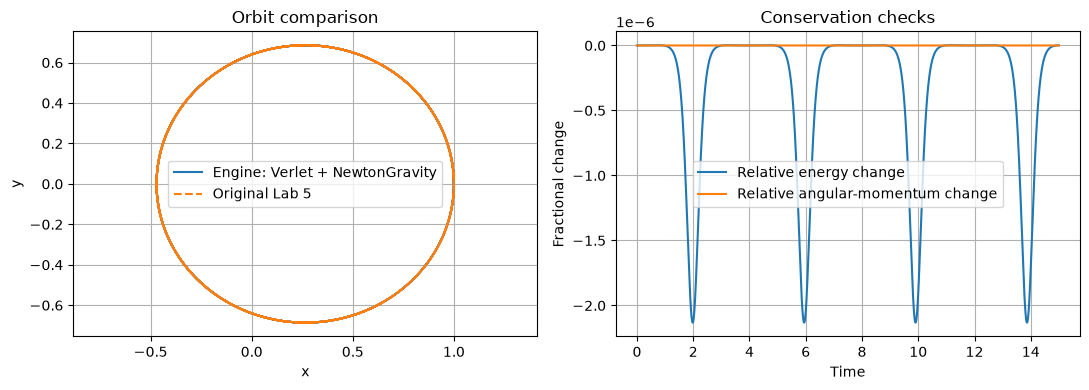

In [ ]:
# Part 3
# Orbit (Labs 5)
# Orignal Process
G = 1
M = 1
def verlet_step(r, v, a, dt, accel_func):
    """One Velocity Verlet step. accel_func(r) returns acceleration at position r."""
    r_new = r + v * dt + 0.5 * a * dt**2
    a_new = accel_func(r_new)
    v_new = v + 0.5 * (a + a_new) * dt
    return r_new, v_new, a_new

def accel_func(r):
    """Acceleration due to gravity at position r."""
    r_mag = np.linalg.norm(r)
    return -G * M * r / r_mag**3

# Initial conditions for a bound elliptical orbit
r = np.array([1.0, 0.0])
v = np.array([0.0, 0.8])   # less than circular speed (=1.0) -> ellipse
a = accel_func(r)
steps = 15000

dt = 0.001
rs = [r.copy()]
vs = [v.copy()]
for _ in range(steps):
    r, v, a = verlet_step(r, v, a, dt, accel_func)
    rs.append(r.copy())
    vs.append(v.copy())
rs = np.array(rs)
vs = np.array(vs)

# Engine Process
orbit_dt = 0.001
orbit_steps = len(rs) - 1
orbit_test_mass = 1e-12

# The tiny orbiting mass makes the central body's motion negligible,
# matching the original lab's fixed-center acceleration model.
orbit_world = World(Verlet())
orbit_center = Body(mass=M, pos=[0.0, 0.0], vel=[0.0, 0.0], radius=1e-12, I=1.0)
orbit_planet = Body(mass=orbit_test_mass, pos=rs[0], vel=vs[0], radius=1e-12)
orbit_world.add_body(orbit_center)
orbit_world.add_body(orbit_planet)
orbit_world.add_force(Newton_Gravity(G=G, softening=1e-9))

list(map(lambda _: orbit_world.step(orbit_dt), range(orbit_steps)))

orbit_history = orbit_world.history
orbit_t = np.fromiter((s["time"] for s in orbit_history), dtype=float)
orbit_positions = np.array([s["positions"] for s in orbit_history])
orbit_relative = orbit_positions[:, 1] - orbit_positions[:, 0]
orbit_energy = np.fromiter((s["total_energy"] for s in orbit_history), dtype=float)
orbit_angular_momentum = np.fromiter((s["angular_momentum"] for s in orbit_history), dtype=float)

position_error = np.linalg.norm(orbit_relative - rs, axis=1)
energy_drift = (orbit_energy - orbit_energy[0]) / abs(orbit_energy[0])
angular_momentum_drift = (orbit_angular_momentum - orbit_angular_momentum[0]) / abs(orbit_angular_momentum[0])

print(f"Maximum position difference: {np.max(position_error):.3e}")
print(f"Maximum relative energy drift: {np.max(np.abs(energy_drift)):.3e}")
print(f"Maximum relative angular-momentum drift: "
      f"{np.max(np.abs(angular_momentum_drift)):.3e}")

# Graph
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(orbit_relative[:, 0], orbit_relative[:, 1], label="Engine Orbit")
axes[0].plot(rs[:, 0], rs[:, 1], "--", label="Original Lab 5 Orbit")
axes[0].set(xlabel="x", ylabel="y", title="Orbit comparison")
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].legend()
axes[0].grid()

axes[1].plot(orbit_t, energy_drift, label="Relative energy change")
axes[1].plot(orbit_t, angular_momentum_drift, label="Relative angular-momentum change")
axes[1].set(xlabel="Time", ylabel="Fractional change", title="Conservation checks")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

The first graph shows the original orbit lab's origanal orbit as well as the engine's orbit overlayed on the same graph. Showing that the outputs of both processes are the same. The second shows the conservation checks.

Part C — An Original Multi-Body Scene (30 points)

Maximum relative energy drift:          7.800e-07
Maximum scaled momentum change:          5.750e-15
Maximum relative angular-momentum drift: 1.616e-14


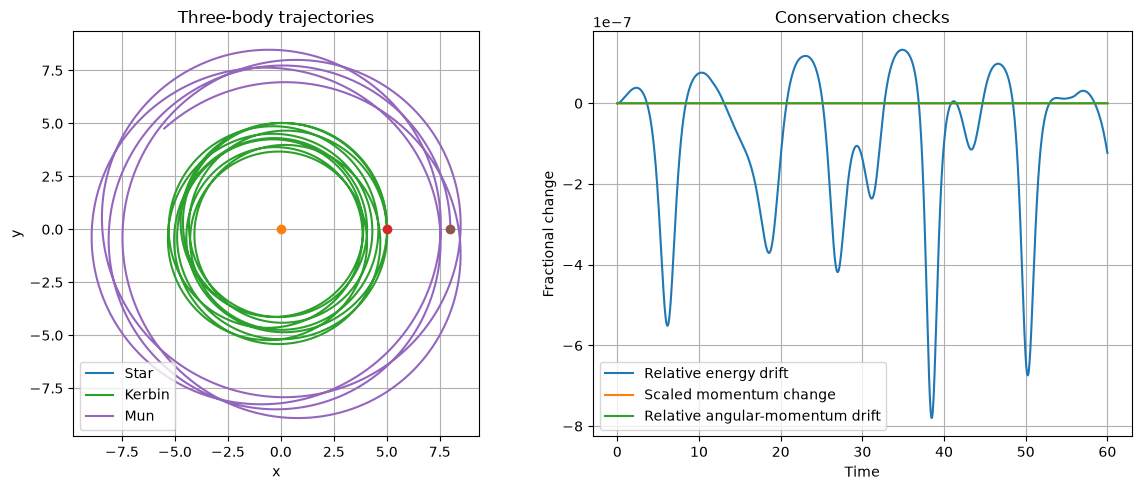

In [ ]:
# Three-body toy solar system: pairwise gravity plus a weak, conservative
# spring coupling between the two orbiting bodies.
system_G = 1.0
system_star_mass = 100.0
system_dt = 0.002
system_steps = 30_000

system_world = World(Verlet())

system_star = Body(system_star_mass, [0.0, 0.0], [0.0, 0.0], radius=0.05)
Kerbin = Body(1.0, [5.0, 0.0], [0.0, np.sqrt(system_G * system_star_mass / 5.0)], radius=0.05)
Mun = Body(0.5, [8.0, 0.0], [0.0, np.sqrt(system_G * system_star_mass / 8.0)], radius=0.05)

# Set the star's initial velocity so total system momentum is approximately zero.
system_star.v = -(Kerbin.m * Kerbin.v + Mun.m * Mun.v) / system_star.m

for body in (system_star, Kerbin, Mun):
    system_world.add_body(body)

system_world.add_force(Newton_Gravity(G=system_G, softening=0.02))
system_world.add_force(Spring(Kerbin, Mun, stiffness=0.02, rest_length=3.0))

for _ in range(system_steps):
    system_world.step(system_dt)

system_history = system_world.history
system_time = np.array([state["time"] for state in system_history])
system_positions = np.array([state["positions"] for state in system_history])

system_energy = np.array([state["total_energy"] for state in system_history])
system_momentum = np.array([state["momentum"] for state in system_history])
system_angular_momentum = np.array([state["angular_momentum"] for state in system_history])

# Normalize momentum drift by a characteristic system momentum, since its
# initial total value is approximately zero.
system_momentum_scale = sum(body.m * np.linalg.norm(body.v) for body in (system_star, Kerbin, Mun))
system_energy_drift = (system_energy - system_energy[0]) / abs(system_energy[0])
system_momentum_drift = (np.linalg.norm(system_momentum - system_momentum[0], axis=1) / system_momentum_scale)
system_angular_drift = (system_angular_momentum - system_angular_momentum[0]) / abs(system_angular_momentum[0])

print(f"Maximum relative energy drift:          {np.max(np.abs(system_energy_drift)):.3e}")
print(f"Maximum scaled momentum change:          {np.max(system_momentum_drift):.3e}")
print(f"Maximum relative angular-momentum drift: {np.max(np.abs(system_angular_drift)):.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, label in enumerate(("Kerbol (Star)", "Kerbin (Planet 1)", "Mun (Planet 2)")):
    axes[0].plot(system_positions[:, i, 0], system_positions[:, i, 1], label=label)
    axes[0].plot(system_positions[0, i, 0], system_positions[0, i, 1], "o")

axes[0].set(xlabel="x", ylabel="y", title="Three-body trajectories", aspect="equal",)
axes[0].legend()
axes[0].grid(True)

axes[1].plot(system_time, system_energy_drift, label="Relative energy drift")
axes[1].plot(system_time, system_momentum_drift, label="Scaled momentum change")
axes[1].plot(system_time, system_angular_drift, label="Relative angular-momentum drift")
axes[1].set(xlabel="Time", ylabel="Fractional change", title="Conservation checks")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

The graph shows the orbits of two bodies around a star. The scond graph shows the conservation checks for the system.